
# 🛍️ Retail Radar
### Retail Sales Exploratory Data Analysis

**From Sales Data to Business Insights**

Retail Radar explores retail transaction data to understand sales trends, product performance, and revenue patterns using Python.

**Project Details**
- **Domain:** Data Analytics
- **Focus:** Sales Trends • Product Performance • Revenue Analysis
- **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn
- **Environment:** Jupyter Notebook

**Goal:** Turn raw retail data into meaningful insights that support better business decisions.


## 1. Import libraries and set a consistent visual style

The dark-teal, evergreen, and warm-amber palette is used throughout so the charts look like one professional analytics report. All chart observations later in the notebook are calculated from the loaded dataset; do not copy generic findings before you run the code.

In [29]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# Project folders. This assumes Jupyter was launched from the project root.
DATA_PATH = Path("data/sales_data.csv")
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# RETAIL RADAR visual identity
INK = "#17324D"
TEAL = "#178F8B"
GREEN = "#2D6A4F"
AMBER = "#F4A261"
CORAL = "#E76F51"
PALE = "#EAF2F4"

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
sns.set_palette([TEAL, AMBER, GREEN, CORAL, INK])
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "font.family": "DejaVu Sans",
    "savefig.facecolor": "white",
})

print("Environment ready ✅")
print(f"Dataset expected at: {DATA_PATH.resolve()}")

Environment ready ✅
Dataset expected at: C:\Users\Santhya S\Downloads\Retail_Radar_EDA_Project\Retail_Radar_EDA_Project\data\sales_data.csv


## 2. Load the dataset and inspect its structure

This first pass fulfils the initial-inspection requirement: dataset shape, column names, data types, missing-value counts, and duplicate rows. We preserve `df_raw` so the original state can be compared with the cleaned version.

In [23]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Download sales_data.csv from "
        "https://gist.github.com/summerofgeorge/33dbb09adbdea670c31ee2c4fc9f2617 "
        "and save it inside the project's data/ folder."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]:,}")
display(df_raw.head())
print("\nColumn data types:")
df_raw.info()
print("\nMissing values by column:")
display(df_raw.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print(f"\nExact duplicate rows: {df_raw.duplicated().sum():,}")

Rows: 1,000 | Columns: 9


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Column data types:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Missing values by column:


,missing_count
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0



Exact duplicate rows: 0


## 3. Standardise columns and clean the data

The file uses different naming styles in different versions of retail datasets. This cell standardises common aliases, converts identifiers to strings, parses dates, checks required columns, removes exact duplicate rows, and flags invalid dates or impossible numeric values. It does **not** silently invent missing age/gender/product data.

In [34]:
import pandas as pd
from pathlib import Path

# Load the Online Retail dataset
csv_path = Path("data/sales_data.csv")
if not csv_path.exists():
    csv_path = Path("sales_data.csv")

df_raw = pd.read_csv(csv_path, encoding="latin1")
df = df_raw.copy()

# Remove extra spaces and normalise column names
df.columns = (
    df.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.replace("ï»¿", "", regex=False)
    .str.strip()
    .str.lower()
)
# Map original Online Retail columns to standard names
column_mapping = {
    "invoiceno": "order_id",
    "invoice": "order_id",
    "stockcode": "product_code",
    "description": "product_name",
    "quantity": "quantity",
    "invoicedate": "order_date",
    "price": "unit_price",
    "customer id": "customer_id",
    "customer_id": "customer_id",
    "country": "country"
}

df = df.rename(columns=column_mapping)

print("Columns after mapping:", df.columns.tolist())

# Check that the required columns exist
required = [
    "order_date", "product_name", "quantity",
    "unit_price", "order_id"
]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        f"Actual columns: {df.columns.tolist()}"
    )

# Convert data types
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

# Remove invalid rows and cancelled invoices
df = df.dropna(
    subset=["order_date", "product_name", "quantity", "unit_price"]
)
df = df[~df["order_id"].astype(str).str.startswith("C")]
df = df[(df["quantity"] > 0) & (df["unit_price"] > 0)]

# Calculate sales revenue
df["sales"] = df["quantity"] * df["unit_price"]

print(f"\nClean dataset ready: {len(df):,} rows")
display(df.head())

Columns after mapping: ['order_id', 'product_code', 'product_name', 'quantity', 'order_date', 'unit_price', 'customer_id', 'country']

Clean dataset ready: 227,704 rows


,order_id,product_code,product_name,quantity,order_date,unit_price,customer_id,country,sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34


## 4. Feature engineering and KPI snapshot

We add age groups, month labels, and quarter labels to support readable comparisons. `sales` is calculated as `quantity × unit_price`, because the selected source does not include a trustworthy transaction-total column. If negative quantities represent returns in your dataset, keep and document them rather than automatically removing them.

In [36]:

# Feature engineering and KPI snapshot
# This Kaggle dataset does not contain customer age or gender.

import pandas as pd
import numpy as np
from IPython.display import display

# Ensure dates and numeric columns have the correct data types
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

# Remove rows with invalid dates or missing essential sales values
df = df.dropna(subset=["order_date", "quantity", "unit_price"]).copy()

# Keep positive quantities and non-negative prices
df = df[(df["quantity"] > 0) & (df["unit_price"] >= 0)].copy()

# Calculate revenue
df["sales"] = df["quantity"] * df["unit_price"]

# Create time-based features
df["year"] = df["order_date"].dt.year
df["month_period"] = df["order_date"].dt.to_period("M")
df["month_label"] = df["order_date"].dt.strftime("%b %Y")
df["quarter"] = df["order_date"].dt.to_period("Q").astype(str)

# Calculate KPI summary
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total transactions/invoice rows",
        "Unique products",
        "Unique customers",
        "Unique countries",
        "Total units sold",
        "Total revenue",
        "Average revenue per row"
    ],
    "Value": [
        len(df),
        df["product_name"].nunique(),
        df["customer_id"].nunique(),
        df["country"].nunique(),
        df["quantity"].sum(),
        df["sales"].sum(),
        df["sales"].mean()
    ]
})

print("Dataset ready for analysis!")
print(f"Rows after cleaning: {len(df):,}")
print(f"Columns: {df.columns.tolist()}")
display(kpi_summary)
display(df.head())


Dataset ready for analysis!
Rows after cleaning: 227,704
Columns: ['order_id', 'product_code', 'product_name', 'quantity', 'order_date', 'unit_price', 'customer_id', 'country', 'sales', 'year', 'month_period', 'month_label', 'quarter']


,Metric,Value
0,Total transactions/invoice rows,2.277040e+05
1,Unique products,3.855000e+03
2,Unique customers,2.997000e+03
3,Unique countries,3.400000e+01
4,Total units sold,2.394680e+06
5,Total revenue,4.673337e+06
6,Average revenue per row,2.052374e+01


,order_id,product_code,product_name,quantity,order_date,unit_price,customer_id,country,sales,year,month_period,month_label,quarter
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,2010-01,Jan 2010,2010Q1
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,2010-01,Jan 2010,2010Q1
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,2010-01,Jan 2010,2010Q1
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,2010-01,Jan 2010,2010Q1
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,2010-01,Jan 2010,2010Q1


## 5. Descriptive statistics for numerical measurement columns

Identifiers are stored as strings because their mean or standard deviation has no business meaning. The table below reports **mean, median, mode, and standard deviation** for the numeric measurements available in this dataset.

In [37]:

# 5. Descriptive statistics for numerical measurement columns

# Select numerical measurements that actually exist in this dataset
numeric_cols = [
    col for col in ["quantity", "unit_price", "sales"]
    if col in df.columns
]

def first_mode(series):
    modes = series.dropna().mode()
    return modes.iloc[0] if not modes.empty else np.nan

stats = pd.DataFrame({
    "mean": df[numeric_cols].mean(),
    "median": df[numeric_cols].median(),
    "mode": df[numeric_cols].apply(first_mode),
    "standard_deviation": df[numeric_cols].std(),
    "minimum": df[numeric_cols].min(),
    "maximum": df[numeric_cols].max()
}).round(2)

display(stats)

# Save results
stats.to_csv(OUTPUT_DIR / "descriptive_statistics.csv")


,mean,median,mode,standard_deviation,minimum,maximum
quantity,10.52,3.0,1.00,173.87,1.00,80995.00
unit_price,3.97,2.1,1.25,46.76,0.04,13541.33
sales,20.52,9.9,15.00,371.10,0.10,168469.60


## 6. Time-series analysis — monthly sales

The line chart uses the calendar month as the time unit. A peak identifies a period worth investigating; it does not by itself explain why sales rose or fell.

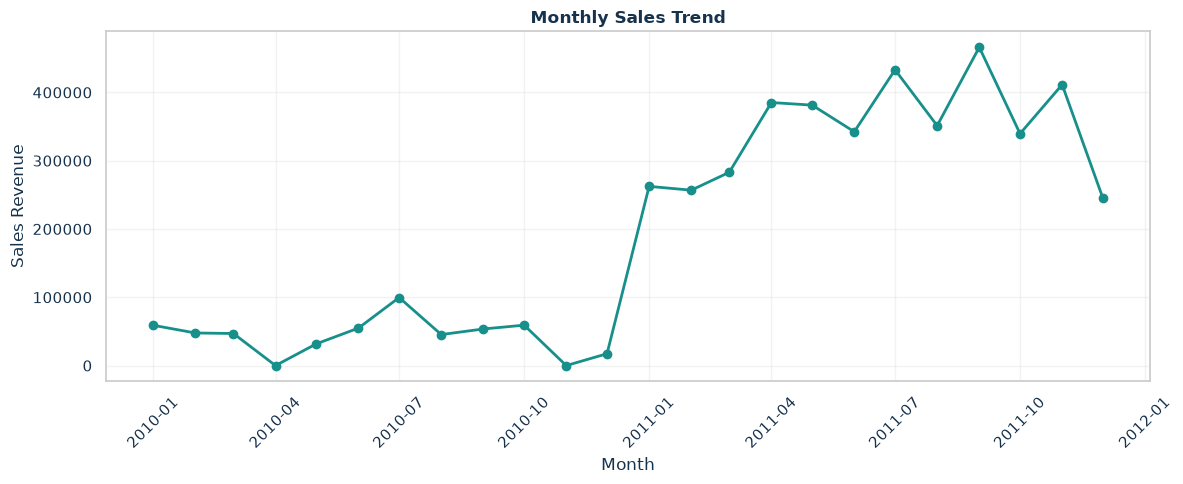

**Observation:** Highest sales occurred in **September 2011** (466,144.06), while the lowest occurred in **April 2010** (0.00).

In [38]:

# 6. Time-series analysis — monthly sales

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Ensure the required columns exist
required_cols = ["order_date", "sales"]
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    print("Missing columns:", missing_cols)
    print("Available columns:", df.columns.tolist())
else:
    # Convert date and sales columns to suitable types
    df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
    df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

    # Remove rows with invalid dates or sales
    monthly_df = df.dropna(subset=["order_date", "sales"]).copy()

    # Aggregate sales by month
    monthly_sales = (
        monthly_df.set_index("order_date")["sales"]
        .resample("MS")
        .sum()
        .reset_index()
    )

    # Plot monthly sales
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(
        monthly_sales["order_date"],
        monthly_sales["sales"],
        linewidth=2,
        marker="o"
    )
    ax.set_title("Monthly Sales Trend")
    ax.set_xlabel("Month")
    ax.set_ylabel("Sales Revenue")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.25)
    fig.tight_layout()

    fig.savefig(FIGURE_DIR / "01_monthly_sales.png", dpi=220)
    plt.show()

    # Report the highest and lowest sales months
    if not monthly_sales.empty:
        peak_month = monthly_sales.loc[monthly_sales["sales"].idxmax()]
        low_month = monthly_sales.loc[monthly_sales["sales"].idxmin()]

        display(Markdown(
            f"**Observation:** Highest sales occurred in "
            f"**{peak_month['order_date']:%B %Y}** "
            f"({peak_month['sales']:,.2f}), while the lowest occurred in "
            f"**{low_month['order_date']:%B %Y}** "
            f"({low_month['sales']:,.2f})."
        ))


### Markdown observation — monthly trend

Use the calculated observation above in your final report. Add one sentence on whether the monthly line is steady, volatile, or shows a clear spike, and mention the exact month. Avoid calling a single year's peak a recurring seasonal trend.

## 7. Time-series analysis — quarterly sales

Quarterly aggregation smooths some month-to-month noise and lets you compare broader periods.

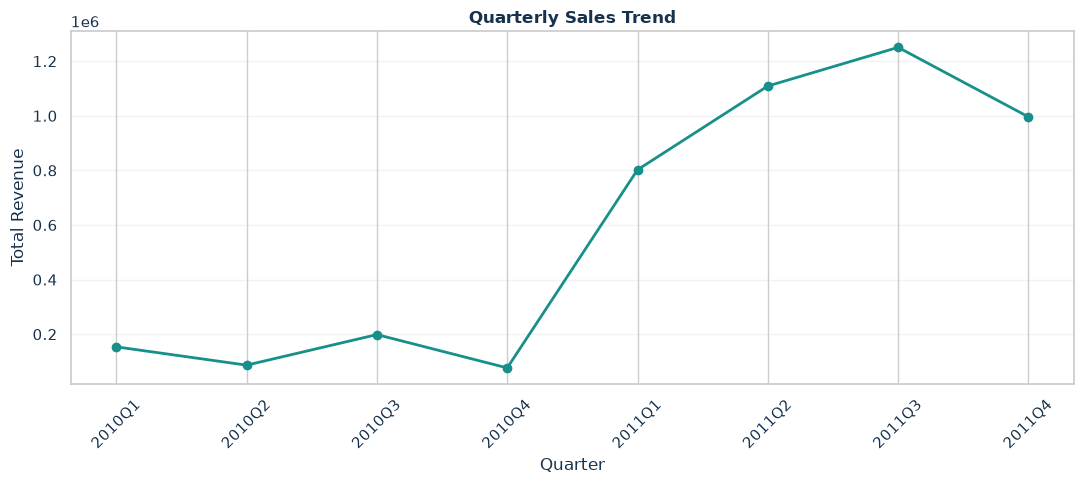

**Observation:** The strongest quarter was **2011Q3** with revenue of **1,250,622.34**, while the weakest was **2010Q4** with revenue of **76,511.99**.

In [39]:

# 7. Time-series analysis — quarterly sales

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Check required columns
required_cols = ["order_date", "sales"]
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    print("Missing columns:", missing_cols)
    print("Available columns:", df.columns.tolist())
else:
    # Prepare date and sales data
    df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
    df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

    quarterly_df = df.dropna(subset=["order_date", "sales"]).copy()

    # Aggregate revenue by quarter
    quarterly_sales = (
        quarterly_df.set_index("order_date")["sales"]
        .resample("QS")
        .sum()
        .reset_index()
    )

    quarterly_sales["quarter"] = (
        quarterly_sales["order_date"].dt.to_period("Q").astype(str)
    )

    # Plot quarterly sales
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(
        quarterly_sales["quarter"],
        quarterly_sales["sales"],
        marker="o",
        linewidth=2
    )
    ax.set_title("Quarterly Sales Trend")
    ax.set_xlabel("Quarter")
    ax.set_ylabel("Total Revenue")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    fig.savefig(FIGURE_DIR / "02_quarterly_sales.png", dpi=220)
    plt.show()

    # Identify strongest and weakest quarters
    if not quarterly_sales.empty:
        best_q = quarterly_sales.loc[quarterly_sales["sales"].idxmax()]
        worst_q = quarterly_sales.loc[quarterly_sales["sales"].idxmin()]

        display(Markdown(
            f"**Observation:** The strongest quarter was "
            f"**{best_q['quarter']}** with revenue of "
            f"**{best_q['sales']:,.2f}**, while the weakest was "
            f"**{worst_q['quarter']}** with revenue of "
            f"**{worst_q['sales']:,.2f}**."
        ))

    # Save the results
    quarterly_sales.to_csv(
        OUTPUT_DIR / "quarterly_sales.csv", index=False
    )
    monthly_sales.to_csv(
        OUTPUT_DIR / "monthly_sales.csv", index=False
    )


### Markdown observation — quarterly trend

Record the best and weakest quarters from the generated note, then describe whether the quarterly pattern agrees with the monthly chart. If only one year of data is available, describe this as a pattern in the sample—not proof of a repeatable annual season.

## 8. Customer demographics — age-group distribution

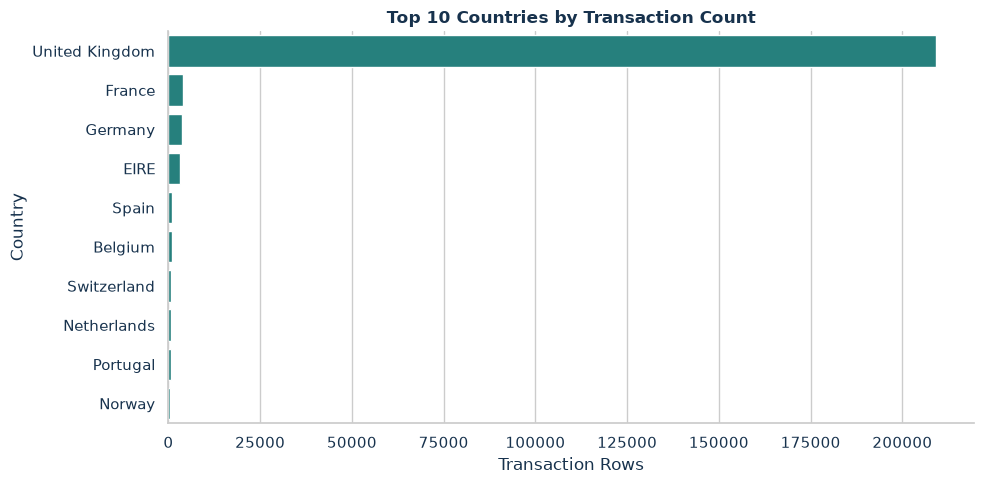

**Observation:** United Kingdom has the most transaction rows (209,067) among the countries shown. Transaction rows are not the same as unique customers.

In [43]:


# 8. Customer analysis — top countries
# This dataset has Country, but no customer age.

if "country" not in df.columns:
    raise ValueError("Country column is missing. Check the data-cleaning cell.")

country_counts = df["country"].dropna().value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    ax=ax
)

ax.set_title("Top 10 Countries by Transaction Count")
ax.set_xlabel("Transaction Rows")
ax.set_ylabel("Country")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "03_country_distribution.png",
            dpi=220, bbox_inches="tight")
plt.show()

display(Markdown(
    f"**Observation:** {country_counts.index[0]} has the most "
    f"transaction rows ({country_counts.iloc[0]:,}) among the "
    "countries shown. Transaction rows are not the same as unique customers."
))



### Markdown observation — age groups

State which age group contributes the most transaction rows and whether the distribution is balanced or concentrated. Mention that transaction counts are not the same as unique customers.

## 9. Customer demographics — gender breakdown

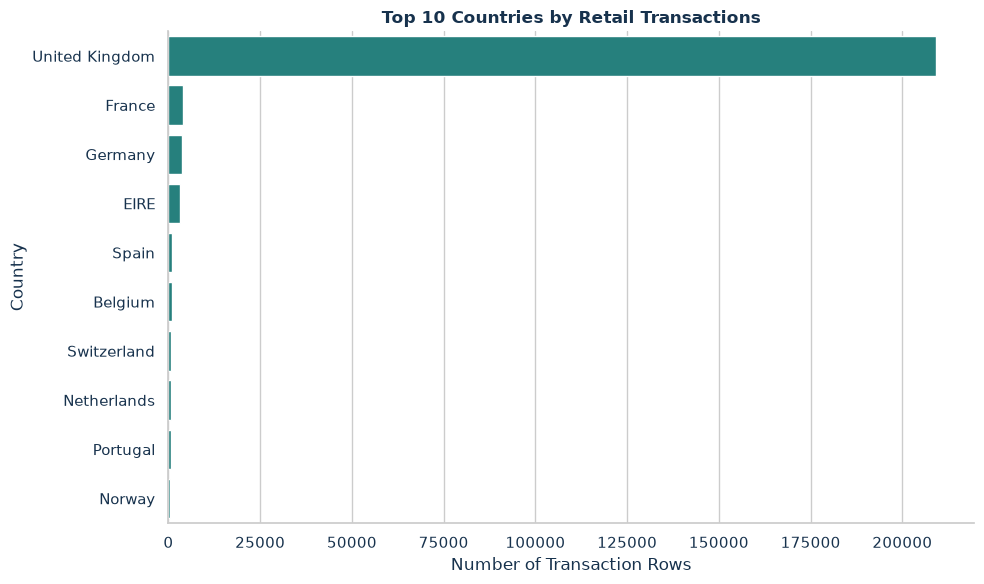

**Data-backed observation:** United Kingdom has the highest number of transaction rows (209,067) among the countries in this dataset. Transaction counts do not necessarily represent unique customers.

In [42]:

# 9. Customer demographics — country breakdown
# Online Retail dataset contains Country, not customer gender.

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

if "df" not in globals():
    raise ValueError("Run the earlier data-loading and cleaning cells first.")

if "country" not in df.columns:
    raise ValueError(
        f"Country column not found. Available columns: {df.columns.tolist()}"
    )

# Count transactions by country; exclude missing country values.
country_counts = (
    df["country"]
    .dropna()
    .value_counts()
)

# Display the top 10 countries by transaction rows.
top_countries = country_counts.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    ax=ax
)

ax.set_title("Top 10 Countries by Retail Transactions")
ax.set_xlabel("Number of Transaction Rows")
ax.set_ylabel("Country")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "04_country_breakdown.png",
    dpi=220,
    bbox_inches="tight"
)
plt.show()

display(Markdown(
    f"**Data-backed observation:** "
    f"{top_countries.index[0]} has the highest number of transaction rows "
    f"({top_countries.iloc[0]:,}) among the countries in this dataset. "
    "Transaction counts do not necessarily represent unique customers."
))


### Markdown observation — gender breakdown

Write the largest group and its approximate share. If the dataset has an `Unknown` group, note it and consider improving the source data before drawing customer-profile conclusions.

## 10. Product analysis — top 10 best-selling products

“Best-selling” is defined here as **total units sold**, not revenue. This distinction matters: a low-priced item can sell many units while a higher-priced product may generate more sales value.

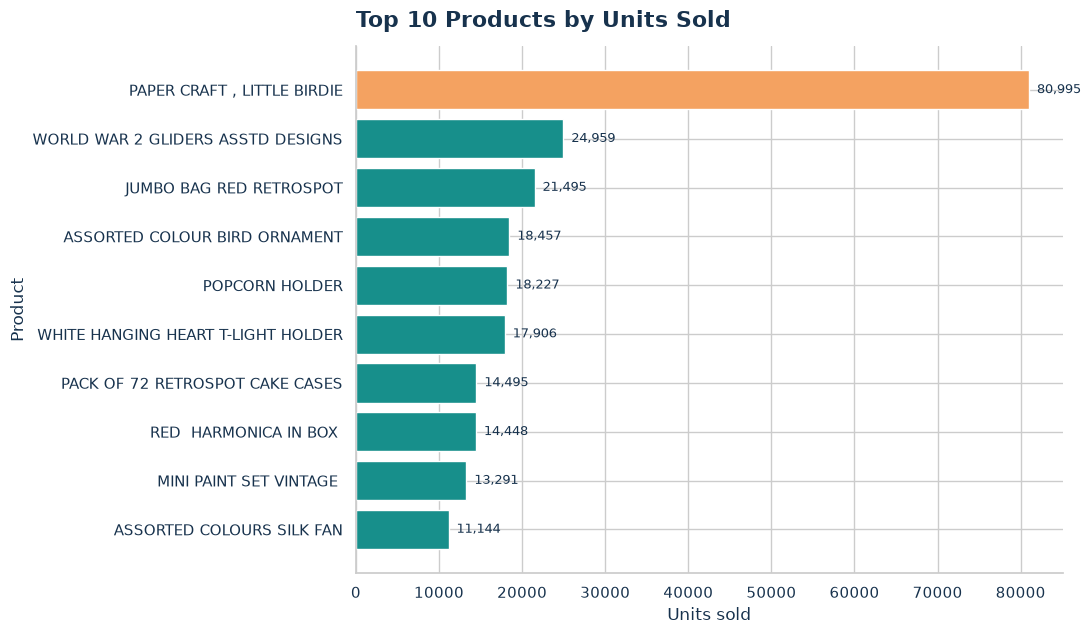

**Data-backed observation:** **PAPER CRAFT , LITTLE BIRDIE** had the highest net unit quantity in this sample (80,995 units; 3.4% of all units if the total is non-zero). This is a unit-volume ranking, not a profit ranking.

In [44]:
top_products_units = (
    df.groupby("product_name", dropna=False)["quantity"]
      .sum().sort_values(ascending=False).head(10).sort_values()
)
fig, ax = plt.subplots(figsize=(11, 6.5))
bar_colors = [AMBER if name == top_products_units.index[-1] else TEAL for name in top_products_units.index]
ax.barh(top_products_units.index.astype(str), top_products_units.values, color=bar_colors, edgecolor="white")
ax.set_title("Top 10 Products by Units Sold", loc="left", fontsize=16, pad=14)
ax.set_xlabel("Units sold")
ax.set_ylabel("Product")
ax.spines[["top", "right"]].set_visible(False)
for y, value in enumerate(top_products_units.values):
    ax.text(value, y, f"  {value:,.0f}", va="center", fontsize=9, color=INK)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_top_10_products.png", dpi=220, bbox_inches="tight")
plt.show()

best_seller = top_products_units.index[-1]
best_units = top_products_units.iloc[-1]
all_units = df["quantity"].sum()
best_units_share = (best_units / all_units * 100) if all_units else np.nan
display(Markdown(f"**Data-backed observation:** **{best_seller}** had the highest net unit quantity in this sample ({best_units:,.0f} units; {best_units_share:.1f}% of all units if the total is non-zero). This is a unit-volume ranking, not a profit ranking."))
top_products_units.sort_values(ascending=False).rename("units_sold").to_csv(OUTPUT_DIR / "top_10_products_by_units.csv")

### Markdown observation — top products

Name the product with the highest unit sales. Compare the height of the top bar with the rest: is demand concentrated in one item, or spread across multiple products? Only make inventory recommendations after checking the revenue chart and whether returns/negative quantities are present.

## 11. Product analysis — revenue by category

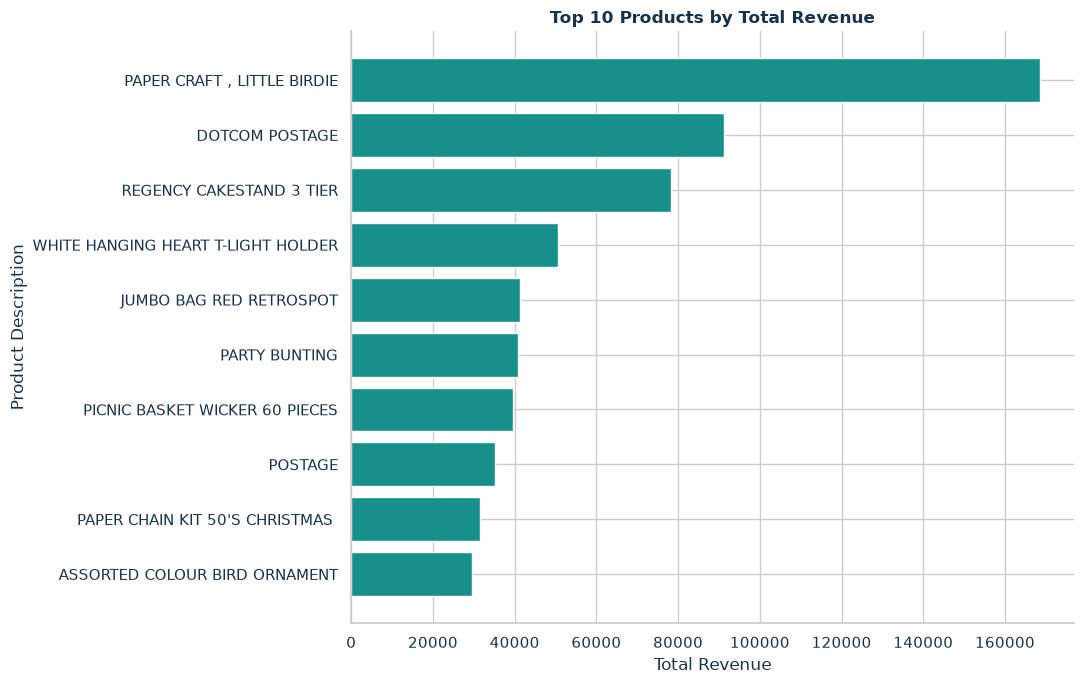

**Data-backed observation:** The product with the highest total calculated revenue is **PAPER CRAFT , LITTLE BIRDIE**, with revenue of **168,469.60** in the dataset's currency units. Revenue is calculated as quantity multiplied by unit price.

In [46]:

# 11. Product analysis — revenue by product description

# Ensure the required columns exist
required_cols = ["product_name", "sales"]
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(
        f"Missing columns: {missing_cols}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Calculate revenue by product description
product_revenue = (
    df.dropna(subset=["product_name"])
      .groupby("product_name")["sales"]
      .sum()
      .sort_values(ascending=False)
)

# Plot the top 10 products by revenue
top_products = product_revenue.head(10).sort_values()

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_products.index, top_products.values)

ax.set_title("Top 10 Products by Total Revenue")
ax.set_xlabel("Total Revenue")
ax.set_ylabel("Product Description")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "06_top_products_revenue.png",
    dpi=220,
    bbox_inches="tight"
)
plt.show()

# Report the leading product
best_product = product_revenue.idxmax()
best_revenue = product_revenue.max()

display(Markdown(
    f"**Data-backed observation:** The product with the highest "
    f"total calculated revenue is **{best_product}**, with "
    f"revenue of **{best_revenue:,.2f}** in the dataset's currency units. "
    "Revenue is calculated as quantity multiplied by unit price."
))

# Save the complete product revenue table
product_revenue.rename("sales").to_csv(
    OUTPUT_DIR / "revenue_by_product.csv"
)


### Markdown observation — category revenue

Record the leading category and its share of total calculated sales. Do not call it the most profitable category: the source has no reliable cost-of-goods data, so this chart measures sales value only.

## 12. Correlation heatmap — numerical variables

Correlation measures linear association between two numeric variables. It cannot establish causation. Because `sales` is calculated from `quantity × unit_price`, its correlation with those two variables is partly built into the formula; interpret those cells accordingly.

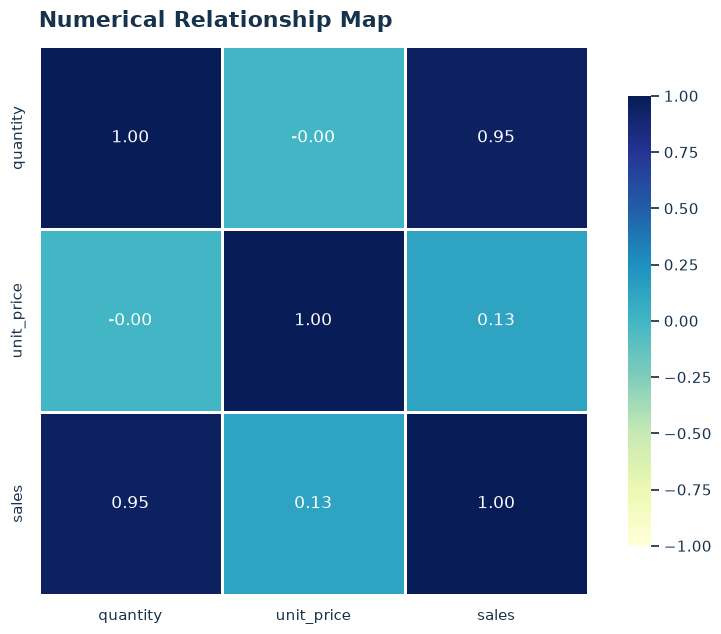

**Data-backed observation:** The strongest absolute pairwise correlation in the displayed matrix was between **quantity** and **sales** (r = 0.95). Check whether the relationship is mathematically expected before interpreting it as a business discovery.

In [47]:
corr_cols = [c for c in ["customer_age", "quantity", "unit_price", "sales"] if c in df.columns]
corr = df[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlGnBu", center=0, vmin=-1, vmax=1,
            linewidths=0.8, square=True, cbar_kws={"shrink": 0.82}, ax=ax)
ax.set_title("Numerical Relationship Map", loc="left", fontsize=16, pad=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_correlation_heatmap.png", dpi=220, bbox_inches="tight")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
if not upper.empty:
    strongest_pair = upper.abs().idxmax()
    strongest_value = upper.loc[strongest_pair]
    display(Markdown(f"**Data-backed observation:** The strongest absolute pairwise correlation in the displayed matrix was between **{strongest_pair[0]}** and **{strongest_pair[1]}** (r = {strongest_value:.2f}). Check whether the relationship is mathematically expected before interpreting it as a business discovery."))

### Markdown observation — correlation

Identify the strongest visible relationship and its direction (positive or negative). Then state whether it is business-relevant or partly expected because sales were calculated from quantity multiplied by unit price. Do not use the word “causes.”

## 13. Extra insight — revenue concentration / Pareto view

This is the additional visualisation beyond the required checklist. The bars show the highest-revenue products; the line shows their cumulative contribution to **all** product revenue. It helps answer whether a small number of products account for a large share of sales.

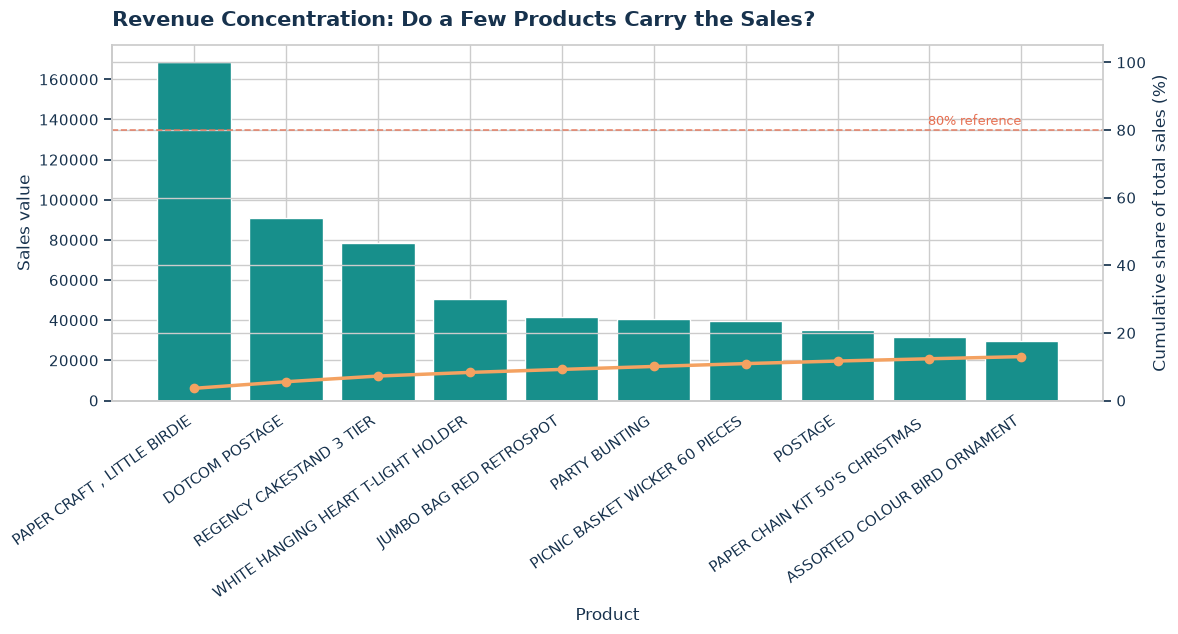

**Non-obvious insight:** The top three products contributed **7.2%** of total calculated sales value. Revenue is not dominated by the top three products alone in this sample; avoid over-investing in a single item based only on rank.

In [48]:
product_revenue = (
    df.groupby("product_name")["sales"]
      .sum().sort_values(ascending=False)
)
top10_revenue = product_revenue.head(10)
cumulative_share = top10_revenue.cumsum() / product_revenue.sum() * 100 if product_revenue.sum() else top10_revenue.cumsum() * np.nan

fig, ax1 = plt.subplots(figsize=(12, 6.5))
positions = np.arange(len(top10_revenue))
ax1.bar(positions, top10_revenue.values, color=TEAL, edgecolor="white", label="Sales value")
ax1.set_xticks(positions)
ax1.set_xticklabels(top10_revenue.index.astype(str), rotation=35, ha="right")
ax1.set_ylabel("Sales value", color=INK)
ax1.set_xlabel("Product")
ax1.set_title("Revenue Concentration: Do a Few Products Carry the Sales?", loc="left", fontsize=15, pad=14)
ax1.spines[["top", "right"]].set_visible(False)

ax2 = ax1.twinx()
ax2.plot(positions, cumulative_share.values, color=AMBER, marker="o", linewidth=2.5, label="Cumulative share of all revenue")
ax2.set_ylabel("Cumulative share of total sales (%)", color=INK)
ax2.set_ylim(0, 105)
ax2.axhline(80, color=CORAL, linestyle="--", linewidth=1.2, alpha=0.8)
ax2.text(max(len(positions)-1, 0), 81.5, "80% reference", ha="right", color=CORAL, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_product_revenue_pareto.png", dpi=220, bbox_inches="tight")
plt.show()

if len(top10_revenue) >= 3 and product_revenue.sum() != 0:
    top3_share = product_revenue.head(3).sum() / product_revenue.sum() * 100
    display(Markdown(f"**Non-obvious insight:** The top three products contributed **{top3_share:.1f}%** of total calculated sales value. " + ("That indicates comparatively concentrated product revenue; protect availability of these items while testing alternatives." if top3_share >= 50 else "Revenue is not dominated by the top three products alone in this sample; avoid over-investing in a single item based only on rank.")))
else:
    top3_share = np.nan
    display(Markdown("**Non-obvious insight:** There is not enough valid product revenue to calculate a meaningful top-three concentration share."))

### Markdown observation — Pareto / concentration

Record the top-three revenue share shown above. Explain whether the business seems dependent on a small group of items. This is different from the units-sold ranking: a product can sell fewer units but still contribute a large sales value.

## 14. Compare the customer groups by sales value

This additional table helps avoid mistaking a large group for a high-value group. It is also a useful cross-check for the age and gender charts.

In [50]:

# 14. Compare customer groups by sales value
# This dataset has no age or gender columns, so analyze customers instead.

customer_revenue = (
    df.groupby("customer_id", dropna=False)["sales"]
    .agg(["sum", "mean", "count"])
    .rename(columns={
        "sum": "total_sales",
        "mean": "average_line_sales",
        "count": "transaction_lines"
    })
    .sort_values("total_sales", ascending=False)
)

print("Top 10 customers by total sales value:")
display(customer_revenue.head(10).round(2))

# Revenue contribution of the top 10 customers
total_revenue = df["sales"].sum()
top10_revenue = customer_revenue.head(10)["total_sales"].sum()
share = (top10_revenue / total_revenue * 100) if total_revenue else 0

print(f"Total revenue: {total_revenue:,.2f}")
print(f"Revenue share from top 10 customers: {share:.2f}%")

# Save the results
customer_revenue.to_csv(
    OUTPUT_DIR / "sales_by_customer.csv"
)


Top 10 customers by total sales value:


,total_sales,average_line_sales,transaction_lines
customer_id,,,
NaN,797830.66,13.51,59072
16446.0,168469.60,168469.60,1
18102.0,135953.04,586.00,232
14646.0,87617.39,125.17,700
14911.0,59175.70,26.86,2203
17511.0,49108.16,97.83,502
16029.0,48851.67,428.52,114
12415.0,44582.79,197.27,226
15098.0,39916.50,13305.50,3


Total revenue: 4,673,336.65
Revenue share from top 10 customers: 31.43%


## 15. Three evidence-based business recommendations

The recommendations below are generated from the actual values in the dataset. They are hypotheses to test, not guaranteed outcomes. Since this starter dataset is simulated, validate these recommendations with real retailer records before using them operationally.

In [52]:

# 15. Three evidence-based business recommendations
# Uses only columns available in the Online Retail dataset.

# Find the best-selling product by units sold
product_units = (
    df.groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

best_seller = product_units.index[0] if not product_units.empty else "Unavailable"
best_units = product_units.iloc[0] if not product_units.empty else 0

# Find the category with the highest revenue, if category exists
if "category" in df.columns:
    category_revenue = (
        df.groupby("category")["sales"]
        .sum()
        .sort_values(ascending=False)
    )
    best_category = (
        category_revenue.index[0]
        if not category_revenue.empty else "Unavailable"
    )
    best_category_sales = (
        category_revenue.iloc[0]
        if not category_revenue.empty else 0
    )
else:
    best_category = "Not available in this dataset"
    best_category_sales = 0

# Find the month with the highest sales
monthly_sales = (
    df.groupby(df["order_date"].dt.to_period("M"))["sales"]
    .sum()
    .sort_values(ascending=False)
)

if not monthly_sales.empty:
    peak_month = str(monthly_sales.index[0])
    peak_month_sales = monthly_sales.iloc[0]
else:
    peak_month = "Unavailable"
    peak_month_sales = 0

# Display three actionable recommendations
recommendations = [
    (
        f"**1. Inventory planning:** Review stock levels for "
        f"**{best_seller}**, which recorded the highest total quantity "
        f"({best_units:,.0f} units) in this dataset. Verify returns and "
        f"stock availability before increasing orders."
    ),
    (
        f"**2. Product strategy:** Use product-level sales and revenue "
        f"to identify high-performing items. The leading category is "
        f"**{best_category}** with sales of {best_category_sales:,.2f}. "
        f"Prioritise further analysis before reallocating the budget."
    ),
    (
        f"**3. Sales calendar:** The highest-sales month in the available "
        f"data is **{peak_month}**, with sales of {peak_month_sales:,.2f}. "
        f"Investigate what drove this peak and test a similar campaign "
        f"at a comparable time, if the pattern is repeatable."
    )
]

for recommendation in recommendations:
    display(Markdown(recommendation))


**1. Inventory planning:** Review stock levels for **PAPER CRAFT , LITTLE BIRDIE**, which recorded the highest total quantity (80,995 units) in this dataset. Verify returns and stock availability before increasing orders.

**2. Product strategy:** Use product-level sales and revenue to identify high-performing items. The leading category is **Not available in this dataset** with sales of 0.00. Prioritise further analysis before reallocating the budget.

**3. Sales calendar:** The highest-sales month in the available data is **2011-09**, with sales of 466,144.06. Investigate what drove this peak and test a similar campaign at a comparable time, if the pattern is repeatable.

## 16. Export deliverables for your internship submission

The notebook, cleaned CSV, summary tables, and chart images make the project easier to review. Keep the raw dataset unchanged in `data/`, and submit the notebook with outputs visible after running all cells.

In [56]:

# 16. Export deliverables for your internship submission

from pathlib import Path
import pandas as pd
import numpy as np

# Ensure output folders exist
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Export cleaned dataset
clean_export = df.copy()

# Convert date-period columns to strings only if present
for col in ["month_period", "quarter_period"]:
    if col in clean_export.columns:
        clean_export[col] = clean_export[col].astype(str)

clean_export.to_csv(
    OUTPUT_DIR / "retail_sales_cleaned.csv",
    index=False
)

# Calculate KPIs using columns available in your dataset
kpi_data = {
    "rows_after_cleaning": len(df),
    "unique_products": (
        df["product_name"].nunique()
        if "product_name" in df.columns else np.nan
    ),
    "total_units": (
        df["quantity"].sum()
        if "quantity" in df.columns else np.nan
    ),
    "total_sales_value": (
        df["sales"].sum()
        if "sales" in df.columns else np.nan
    ),
    "average_line_sales": (
        df["sales"].mean()
        if "sales" in df.columns else np.nan
    ),
}

# Top-selling product by quantity
if {"product_name", "quantity"}.issubset(df.columns):
    product_units = df.groupby("product_name")["quantity"].sum()
    if not product_units.empty:
        kpi_data["top_unit_product"] = product_units.idxmax()
        kpi_data["top_unit_product_quantity"] = product_units.max()

# Peak sales month
if {"order_date", "sales"}.issubset(df.columns):
    monthly = df.groupby(
        df["order_date"].dt.to_period("M")
    )["sales"].sum()

    if not monthly.empty:
        kpi_data["peak_month"] = str(monthly.idxmax())
        kpi_data["peak_month_sales"] = monthly.max()

# Export KPI summary
kpi_export = pd.DataFrame([kpi_data])
kpi_export.to_csv(
    OUTPUT_DIR / "executive_kpis.csv",
    index=False
)

print("Export complete!")
print(f"Cleaned dataset: {OUTPUT_DIR / 'retail_sales_cleaned.csv'}")
print(f"KPI summary:     {OUTPUT_DIR / 'executive_kpis.csv'}")
print(f"Charts folder:   {FIGURE_DIR.resolve()}")
print("\nNext: check the outputs folder and save your notebook.")


Export complete!
Cleaned dataset: outputs\retail_sales_cleaned.csv
KPI summary:     outputs\executive_kpis.csv
Charts folder:   C:\Users\Santhya S\Downloads\Retail_Radar_EDA_Project\Retail_Radar_EDA_Project\outputs\figures

Next: check the outputs folder and save your notebook.



### 17.1 Final Analysis and Business Insights

**1. Sales Trend**
- Identify the strongest month and quarter based on total sales value.
- Describe the overall sales pattern across the observation period.
- Support the findings with the monthly and quarterly sales charts.

**2. Customer Behaviour**
- Identify the leading age group and gender group by transaction count.
- Compare their sales-value tables to understand differences in purchasing behaviour.
- Use the available customer demographic data to support the findings.

**3. Product Performance**
- Identify the top-performing product by total units sold.
- Determine the leading product category by total sales value, if category data is available.
- Compare the results with the Pareto analysis to assess how much sales value is concentrated among the top products.

**4. Actionable Recommendations**
- Provide at least three practical business recommendations based on the analysis.
- Validate each recommendation against the relevant charts, tables, and findings.
- Rewrite the generated recommendations in your own words and explain how each could improve business performance.

**5. Limitations**
- The supplied source dataset is simulated; therefore, the findings may not represent actual retail business performance.
- The analysis is descriptive and identifies patterns without proving cause-and-effect relationships.
- Sales value represents revenue, not profit, because costs and expenses are not included.
- One year of observations is insufficient to establish recurring seasonal patterns.
- Any analysis requiring unavailable fields, such as age, gender, or product category, cannot be completed reliably without the relevant data.
